# Week 2 · Exploratory Data Analysis & Anomaly Detection

**Author:** Junyue Li · **Data:** `data/delivery_leg_telemetry_train.csv` (2,400 legs). The holdout file stays sealed until week 4 and is not loaded here.

**Goal:** describe every column, visualize its distribution, and flag anomalies (GPS/telematics dropouts, duplicate records, unrealistic times and values) so cleaning decisions can be made **before** any modelling.

**Notebook map**
1. Setup and schema check
2. Descriptive statistics
3. Missing values: how much, and is it random?
4. Numeric distributions (annotated)
5. Categorical distributions
6. Anomaly checks
   - 6.1 Duplicate and near-duplicate records
   - 6.2 GPS / telematics dropouts and implausible speeds
   - 6.3 Unrealistic times and value combinations
   - 6.4 Values piled at a hard cap
   - 6.5 Multivariate outliers (Isolation Forest)
7. Relationships to check before modelling (engineer's notes)
8. **Prioritised data-quality issues and cleaning decisions**

> `carrier_close_code` is a post-outcome field (data dictionary). It appears below only for data-quality checks and is never used as a feature.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("..") / "data" / "delivery_leg_telemetry_train.csv"
df = pd.read_csv(DATA)
df["is_late"] = 1 - df["on_time_delivery"]          # positive class = late (week 1 framing)

NUM = ["scheduled_window_minutes", "leg_distance_km", "departure_hour",
       "avg_speed_kmh", "stop_sequence_position"]
CAT = ["region", "weather_condition", "vehicle_class", "demand_spike_flag"]
FEATURES = NUM + CAT
print(df.shape)
df.head()

(2400, 13)


,leg_id,region,scheduled_window_minutes,leg_distance_km,departure_hour,weather_condition,avg_speed_kmh,vehicle_class,stop_sequence_position,demand_spike_flag,carrier_close_code,on_time_delivery,is_late
0,TR-00001,Southeast,203.0,173.82,2.0,Clear,104.0,Heavy Rigid,19.0,True,1.0,1,0
1,TR-00002,Northeast,123.0,5.50,6.0,Clear,13.0,Light Van,18.0,False,1.0,1,0
2,TR-00003,Northeast,372.0,8.62,6.0,Clear,67.0,Light Van,11.0,False,1.0,1,0
3,TR-00004,West Coast,446.0,378.43,9.0,Clear,40.0,Light Van,4.0,NaN,1.0,1,0
4,TR-00005,Mountain,236.0,45.19,11.0,Severe Storm,75.0,Light Van,NaN,False,1.0,0,1


## 1. Schema check

Compare the loaded types with the data dictionary.

In [2]:
schema = pd.DataFrame({
    "pandas_dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
schema

,pandas_dtype,n_unique,example
leg_id,str,2400,TR-00001
region,str,6,Southeast
scheduled_window_minutes,float64,447,203.0
leg_distance_km,float64,2062,173.82
departure_hour,float64,24,2.0
weather_condition,str,6,Clear
avg_speed_kmh,float64,98,104.0
vehicle_class,str,5,Heavy Rigid
stop_sequence_position,float64,22,19.0
demand_spike_flag,object,2,True


In [3]:
# Integer-valued columns stored as float (because of NaNs) - are they really whole numbers?
for c in ["departure_hour", "stop_sequence_position", "scheduled_window_minutes"]:
    vals = df[c].dropna()
    print(f"{c:28s} all whole numbers: {np.allclose(vals, vals.round())}")
print("demand_spike_flag values:", df["demand_spike_flag"].unique())
print("carrier_close_code values:", df["carrier_close_code"].unique())

departure_hour               all whole numbers: True
stop_sequence_position       all whole numbers: True
scheduled_window_minutes     all whole numbers: True
demand_spike_flag values: [True False nan]
carrier_close_code values: [ 1.  0. nan]


**Notes**
- `departure_hour`, `stop_sequence_position` and `scheduled_window_minutes` are whole numbers stored as `float` only because they contain missing values. Use nullable `Int64` when cleaning.
- `demand_spike_flag` is read as `object` (`True` / `False` / NaN). It needs an explicit boolean conversion that keeps missing values; it should not become `False`.
- `leg_id` is unique (checked in 6.1). It is an identifier only.

## 2. Descriptive statistics

In [4]:
desc = df[NUM].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = df[NUM].skew()
desc["n_at_max"] = [(df[c] == df[c].max()).sum() for c in NUM]
desc.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,n_at_max
scheduled_window_minutes,2225.0,275.67,137.52,31.00,38.00,56.00,156.00,282.00,395.00,480.0,480.0,480.0,-0.11,137
leg_distance_km,2232.0,230.44,124.57,1.51,6.09,26.02,123.38,237.88,337.92,420.0,420.0,420.0,-0.13,129
departure_hour,2240.0,12.58,6.95,0.00,0.00,1.00,7.00,13.00,19.00,23.0,23.0,23.0,-0.12,180
avg_speed_kmh,2243.0,61.35,29.22,8.00,9.00,14.10,36.00,62.00,87.50,105.0,105.0,105.0,-0.09,164
stop_sequence_position,2231.0,12.36,6.37,1.00,1.00,2.00,7.00,13.00,18.00,22.0,22.0,22.0,-0.10,191


In [5]:
cat_summary = pd.concat(
    {c: df[c].value_counts(dropna=False).rename("n").to_frame()
          .assign(pct=lambda t: (t.n / len(df) * 100).round(1)) for c in CAT}, names=["column", "level"])
cat_summary

n   pct
column            level                   
region            West Coast     475  19.8
                  Midwest        458  19.1
                  Southwest      456  19.0
                  Southeast      442  18.4
                  Northeast      435  18.1
                  Mountain       134   5.6
weather_condition Clear         1546  64.4
                  NaN            163   6.8
                  Snow           152   6.3
                  Light Rain     143   6.0
                  Fog            140   5.8
                  Severe Storm   133   5.5
                  Heavy Rain     123   5.1
vehicle_class     Light Van     1574  65.6
                  NaN            186   7.8
                  Heavy Rigid    181   7.5
                  Refrigerated   169   7.0
                  Medium Rigid   151   6.3
                  Articulated    139   5.8
demand_spike_flag False         1125  46.9
                  True          1119  46.6
                  NaN            156   6.5

**What stands out**
- All numeric columns are spread fairly evenly between their min and max (|skew| < 0.2), with **no long tails**. The one irregularity is that **every column has a block of rows sitting exactly at its maximum** (`n_at_max` = 129–191). Section 6.4 follows this up.
- `vehicle_class` is dominated by Light Van (66%). `weather_condition` is 64% Clear.
- Overall late rate: **17.3%** (week 2 task 1).

## 3. Missing values

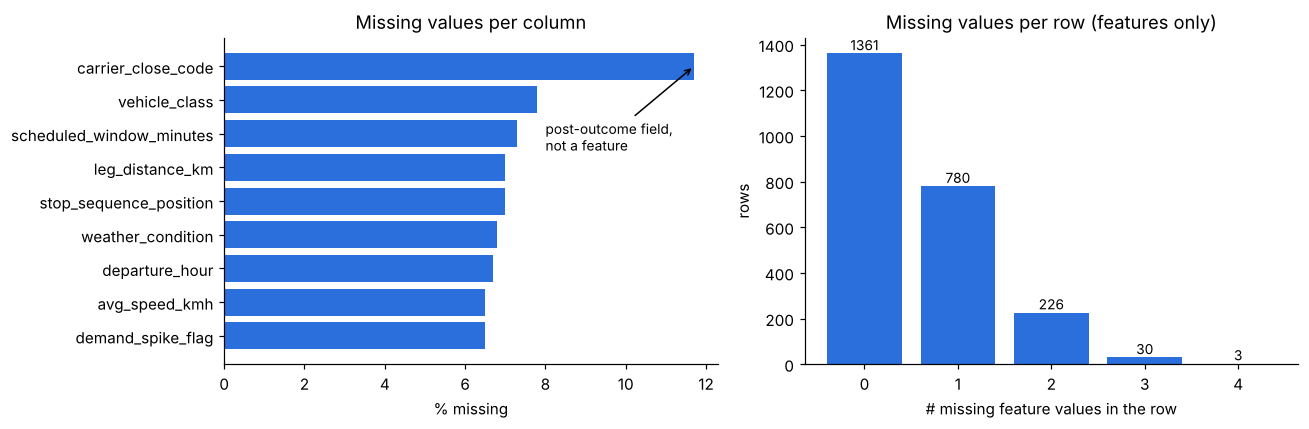

,n_missing,pct
carrier_close_code,281,11.7
vehicle_class,186,7.8
scheduled_window_minutes,175,7.3
leg_distance_km,168,7.0
stop_sequence_position,169,7.0
weather_condition,163,6.8
departure_hour,160,6.7
avg_speed_kmh,157,6.5
demand_spike_flag,156,6.5


In [6]:
miss = pd.DataFrame({"n_missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(1)})
miss = miss[miss.n_missing > 0].sort_values("pct", ascending=False)

feat_missing = df[FEATURES].isna().sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(miss.index, miss.pct, color="#2a6fdb")
axes[0].invert_yaxis()
axes[0].set_xlabel("% missing")
axes[0].set_title("Missing values per column")
axes[0].annotate("post-outcome field,\nnot a feature", xy=(miss.loc["carrier_close_code", "pct"], 0),
                 xytext=(8, 2.5), arrowprops=dict(arrowstyle="->"), fontsize=9)

vc = feat_missing.value_counts().sort_index()
axes[1].bar(vc.index.astype(str), vc.values, color="#2a6fdb")
axes[1].set_xlabel("# missing feature values in the row")
axes[1].set_ylabel("rows")
axes[1].set_title("Missing values per row (features only)")
for x, y in zip(vc.index.astype(str), vc.values):
    axes[1].text(x, y, str(y), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()
miss

In [7]:
# Is missingness random? Compare co-missingness and the late rate when a value is missing vs present.
co = df[FEATURES].isna().astype(int).corr()
print("max |correlation| between missing-indicators of two different columns:",
      round(co.where(~np.eye(len(co), dtype=bool)).abs().max().max(), 3))

rows = []
for c in FEATURES:
    m = df[c].isna()
    rows.append({"column": c, "n_missing": int(m.sum()),
                 "late_rate_if_missing": df.loc[m, "is_late"].mean(),
                 "late_rate_if_present": df.loc[~m, "is_late"].mean()})
mnar = pd.DataFrame(rows).set_index("column")
mnar["diff_pp"] = (mnar.late_rate_if_missing - mnar.late_rate_if_present) * 100
mnar.round(3).sort_values("diff_pp", ascending=False)

max |correlation| between missing-indicators of two different columns: 0.047


,n_missing,late_rate_if_missing,late_rate_if_present,diff_pp
column,,,,
departure_hour,160,0.238,0.168,6.920
weather_condition,163,0.196,0.171,2.511
scheduled_window_minutes,175,0.194,0.171,2.305
vehicle_class,186,0.194,0.171,2.237
stop_sequence_position,169,0.178,0.173,0.495
leg_distance_km,168,0.167,0.173,-0.672
avg_speed_kmh,157,0.166,0.173,-0.782
demand_spike_flag,156,0.160,0.174,-1.354
region,0,NaN,0.173,NaN


**Interpretation**
- **1,039 of 2,400 rows (43%) miss at least one feature value**, but almost always just one or two. Dropping incomplete rows would discard 43% of the data, so that is **not an option**.
- Missing indicators are almost uncorrelated with each other (max |r| ≈ 0.05). Gaps occur independently per column rather than whole sources failing together, which fits partial joins rather than a broken upstream system.
- **`departure_hour` missing is informative:** legs with no departure hour are late **23.8%** of the time vs **16.8%** when it is present (+7 pp). That points to missing not at random, possibly the same timing problem behind the midnight join. **Decision:** impute *and* add a `departure_hour_missing` indicator. The other columns differ by only ±2–3 pp.

## 4. Numeric distributions (annotated)

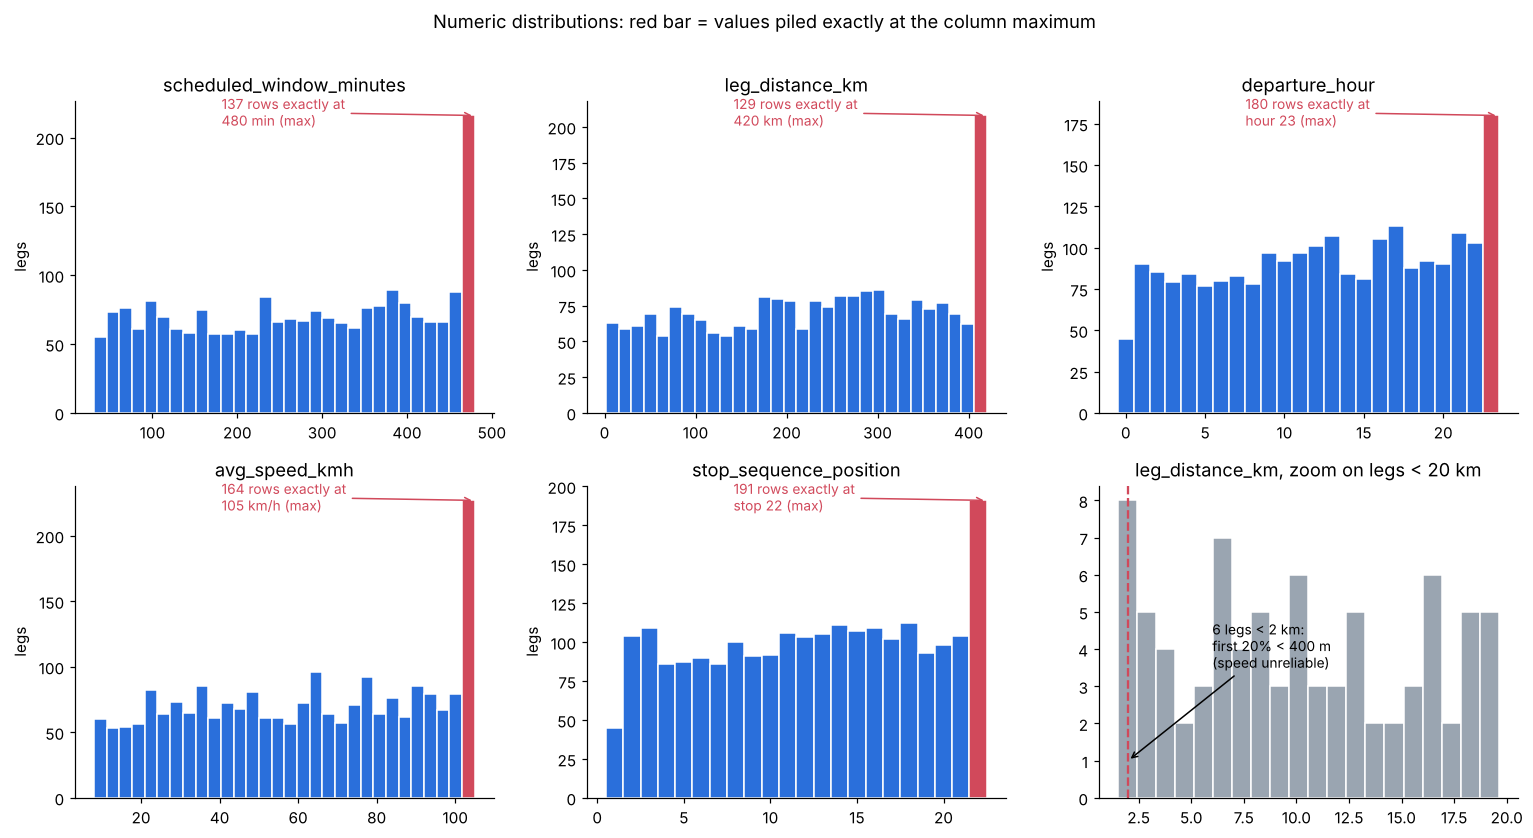

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
notes = {
    "scheduled_window_minutes": "480 min",
    "leg_distance_km": "420 km",
    "departure_hour": "hour 23",
    "avg_speed_kmh": "105 km/h",
    "stop_sequence_position": "stop 22",
}
for ax, c in zip(axes.flat, NUM):
    vals = df[c].dropna()
    bins = np.arange(0, 25) - 0.5 if c == "departure_hour" else (np.arange(0.5, 23.5) if c == "stop_sequence_position" else 30)
    n, edges, patches = ax.hist(vals, bins=bins, color="#2a6fdb", edgecolor="white")
    patches[-1].set_facecolor("#d1495b")
    mx = vals.max(); k = (vals == mx).sum()
    ax.annotate(f"{k} rows exactly at\n{notes[c]} (max)", xy=(edges[-1], n[-1]),
                xytext=(0.35, 0.92), textcoords="axes fraction", fontsize=9, color="#d1495b",
                arrowprops=dict(arrowstyle="->", color="#d1495b"))
    ax.set_title(c)
    ax.set_ylabel("legs")

ax = axes.flat[5]
d = df.leg_distance_km.dropna()
ax.hist(d[d < 20], bins=20, color="#9aa5b1", edgecolor="white")
ax.axvline(2, color="#d1495b", ls="--")
ax.annotate(f"{(d < 2).sum()} legs < 2 km:\nfirst 20% < 400 m\n(speed unreliable)", xy=(2, 1), xytext=(6, 3.5),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_title("leg_distance_km, zoom on legs < 20 km")
plt.suptitle("Numeric distributions: red bar = values piled exactly at the column maximum", y=1.01)
plt.tight_layout()
plt.show()

**Reading the plots**
- Apart from the red bars, every distribution is close to **flat/uniform** across its range. There is no natural peak (for example, no rush hour in `departure_hour`).
- The **red bars are anomalies**: each column has a spike at its maximum that is 1.5–2× the height of the neighbouring bins. Real-world distance and speed would *taper off* towards their extremes; they would not pile up at one value. That pattern means **values were clipped (capped)** somewhere upstream. See 6.4.
- **Stop 1 (45 legs) and hour 0 (45 legs) are both about half as common as their neighbours.** Together with the spikes at stop 22 and hour 23, this looks like values being shifted to the top of the range, not like natural variation.
- **Hour 23 has 180 legs, about 2× any other hour.** The README warns that the telematics/dispatch join misbehaves on shifts that cross midnight. Hour 23 is where clipped post-midnight times would land.

## 5. Categorical distributions

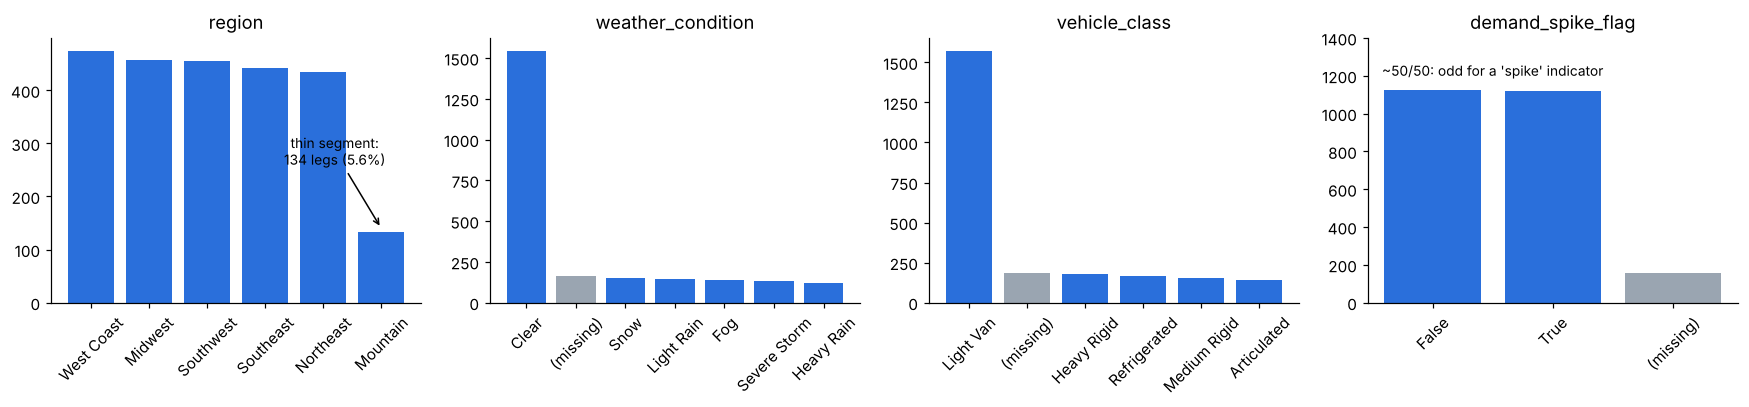

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes, CAT):
    vc = df[c].astype("object").fillna("(missing)").value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=["#9aa5b1" if i == "(missing)" else "#2a6fdb" for i in vc.index])
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
axes[0].annotate("thin segment:\n134 legs (5.6%)", xy=(5, 140), xytext=(4.2, 260), ha="center",
                 arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[3].set_ylim(0, 1400)
axes[3].text(0.5, 1200, "~50/50: odd for a 'spike' indicator", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

- **Mountain** is a thin region (134 legs, 19 late), so it needs explicit stratification later.
- **`demand_spike_flag` is True for half of all legs**, which is unusual for a flag meant to mark surges. Week 2 task 1 also found it has **no relationship to lateness** (p = 0.90). Its definition should be confirmed with product.

## 6. Anomaly checks

### 6.1 Duplicate and near-duplicate records

In [10]:
feat_cols = [c for c in df.columns if c not in ("leg_id", "on_time_delivery", "is_late", "carrier_close_code")]
rounded = df.copy()
rounded["leg_distance_km"] = rounded["leg_distance_km"].round(0)
checks = {
    "duplicate leg_id": df["leg_id"].duplicated().sum(),
    "exact duplicate rows (all columns except leg_id)": df.drop(columns="leg_id").duplicated().sum(),
    "duplicate feature vectors (ignoring id, label, close code)": df.duplicated(subset=feat_cols).sum(),
    "near-duplicates (distance rounded to 1 km)": rounded.duplicated(subset=feat_cols).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
duplicate leg_id,0
exact duplicate rows (all columns except leg_id),0
"duplicate feature vectors (ignoring id, label, close code)",0
near-duplicates (distance rounded to 1 km),0


**No duplicates of any kind are visible.** That is *not* evidence that the README's duplicate problem is absent. The join described there (vehicle ID + 15-minute window) duplicates **telematics** onto **dispatch** records, and the extract has **no vehicle ID, no timestamp and a fresh `leg_id` per row**. A duplicated leg would therefore show up with a new id and possibly slightly different values. **Duplicates can't be detected with the columns we have.** The hour-23 spike (6.3) is the only visible trace of the problem.

**Decision:** we can't deduplicate. Flag hour-23 rows as suspect, and ask Carlos for `vehicle_id` + timestamp so true duplicates can be found.

### 6.2 GPS / telematics dropouts and implausible speeds

In [11]:
speed, dist = df["avg_speed_kmh"], df["leg_distance_km"]
gps = {
    "speed missing (no telematics reading)": speed.isna().sum(),
    "speed AND distance missing": (speed.isna() & dist.isna()).sum(),
    "speed < 15 km/h (crawl / possible stalled ping)": (speed < 15).sum(),
    "  ...of which on legs > 200 km": ((speed < 15) & (dist > 200)).sum(),
    "speed at 105 km/h cap": (speed == 105).sum(),
    "heavy trucks (Articulated / Heavy Rigid) >= 100 km/h": ((speed >= 100) & df.vehicle_class.isin(["Articulated", "Heavy Rigid"])).sum(),
    "legs < 2 km (first 20% < 400 m, per ML engineer)": (dist < 2).sum(),
}
pd.Series(gps, name="count").to_frame()

,count
speed missing (no telematics reading),157
speed AND distance missing,7
speed < 15 km/h (crawl / possible stalled ping),113
...of which on legs > 200 km,55
speed at 105 km/h cap,164
heavy trucks (Articulated / Heavy Rigid) >= 100 km/h,84
"legs < 2 km (first 20% < 400 m, per ML engineer)",6


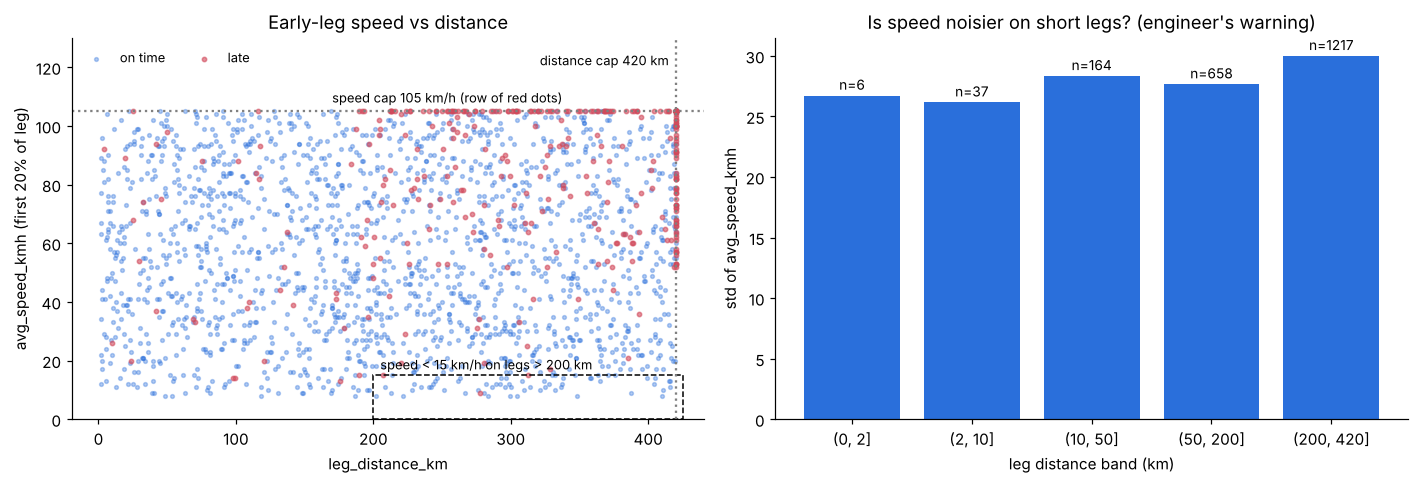

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ok = df[["leg_distance_km", "avg_speed_kmh", "is_late"]].dropna()
ax.scatter(ok.leg_distance_km[ok.is_late == 0], ok.avg_speed_kmh[ok.is_late == 0], s=6, alpha=.35, color="#2a6fdb", label="on time")
ax.scatter(ok.leg_distance_km[ok.is_late == 1], ok.avg_speed_kmh[ok.is_late == 1], s=8, alpha=.6, color="#d1495b", label="late")
ax.axhline(105, ls=":", color="grey"); ax.axvline(420, ls=":", color="grey")
ax.text(170, 108, "speed cap 105 km/h (row of red dots)", fontsize=8.5)
ax.text(415, 125, "distance cap 420 km", fontsize=8.5, ha="right", va="top")
ax.add_patch(plt.Rectangle((200, 0), 225, 15, fill=False, ec="black", lw=1, ls="--"))
ax.text(205, 17, "speed < 15 km/h on legs > 200 km", fontsize=8.5)
ax.set_xlabel("leg_distance_km"); ax.set_ylabel("avg_speed_kmh (first 20% of leg)")
ax.set_ylim(0, 130); ax.legend(loc="upper left", ncol=2, frameon=False, fontsize=8.5)
ax.set_title("Early-leg speed vs distance")

ax = axes[1]
band = pd.cut(df.leg_distance_km, [0, 2, 10, 50, 200, 420])
g = df.groupby(band, observed=True).avg_speed_kmh.agg(["count", "std"])
ax.bar(g.index.astype(str), g["std"], color="#2a6fdb")
for i, (n, s) in enumerate(zip(g["count"], g["std"])):
    ax.text(i, s + 0.5, f"n={n}", ha="center", fontsize=9)
ax.set_ylabel("std of avg_speed_kmh"); ax.set_xlabel("leg distance band (km)")
ax.set_title("Is speed noisier on short legs? (engineer's warning)")
plt.tight_layout(); plt.show()

**Findings**
- **Explicit dropouts:** `avg_speed_kmh` is missing for 157 legs (6.5%). These are the clearest GPS/telematics dropouts. Speed and distance are missing *together* in only a handful of rows, so most gaps are telematics-only.
- **Possible stalled pings:** speed < 15 km/h on legs > 200 km. A truck averaging under 15 km/h over the first 40+ km of a long leg is possible only in severe congestion. These could equally be pings recorded while the vehicle was still at the depot. **Flag them; don't drop them.**
- **Heavy trucks at ≥ 100 km/h:** above typical US truck speed limits (≈ 65–70 mph ≈ 105–113 km/h on interstates, lower elsewhere). It's not impossible, but implausible as an *average* over the start of a leg that includes leaving the depot.
- **Short-leg noise (engineer's warning):** only **6 legs are < 2 km**, and the speed spread on short legs is *not* larger than on long legs in this file. The issue is real in principle but affects very few rows here. **Decision:** mask speed for legs < 2 km instead of building a special treatment.

### 6.3 Unrealistic times and value combinations

In [13]:
travel_h = df.leg_distance_km / df.avg_speed_kmh          # straight-line km / early speed: a rough lower bound
win_h = df.scheduled_window_minutes / 60
timing = {
    "departure_hour outside 0-23": ((df.departure_hour < 0) | (df.departure_hour > 23)).sum(),
    "departure_hour == 23 (expected ~95 if uniform)": (df.departure_hour == 23).sum(),
    "implied travel time > 8 h (more than one shift)": (travel_h > 8).sum(),
    "implied travel time > 24 h": (travel_h > 24).sum(),
    "late-route stop (>= 15) departing 00:00-03:59": ((df.stop_sequence_position >= 15) & (df.departure_hour <= 3)).sum(),
    "window <= 60 min but leg > 300 km": ((df.scheduled_window_minutes <= 60) & (df.leg_distance_km > 300)).sum(),
}
print("max implied travel time (h):", round(travel_h.max(), 1))
pd.Series(timing, name="count").to_frame()

max implied travel time (h): 51.3


,count
departure_hour outside 0-23,0
departure_hour == 23 (expected ~95 if uniform),180
implied travel time > 8 h (more than one shift),351
implied travel time > 24 h,43
late-route stop (>= 15) departing 00:00-03:59,98
window <= 60 min but leg > 300 km,31


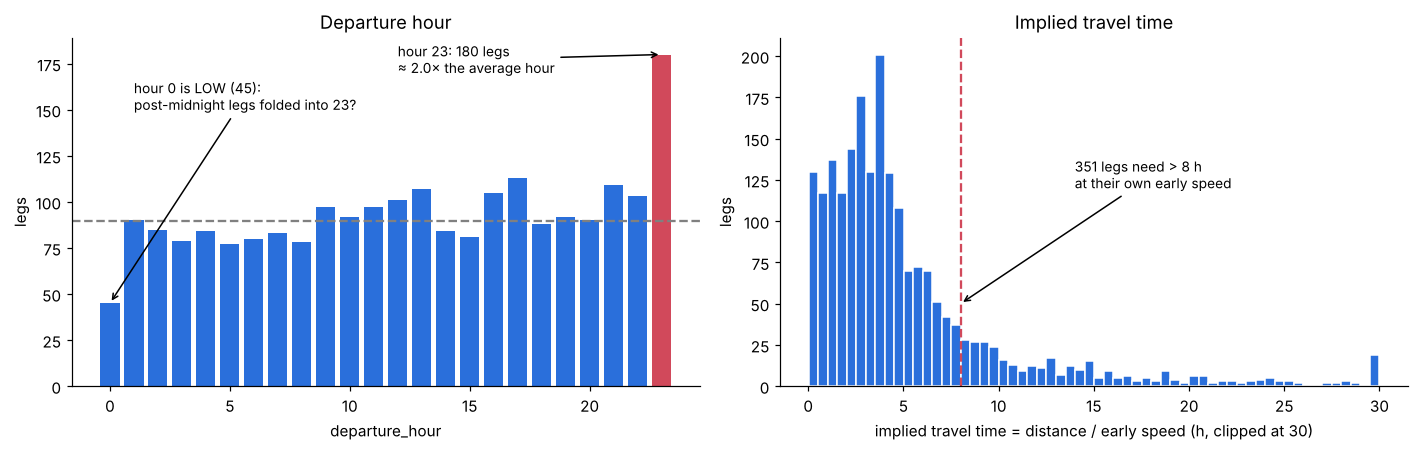

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
hc = df.departure_hour.value_counts().sort_index()
ax.bar(hc.index, hc.values, color=["#d1495b" if h == 23 else "#2a6fdb" for h in hc.index])
ax.axhline(hc.drop(23).mean(), ls="--", color="grey")
ax.annotate(f"hour 23: {hc[23]} legs\n≈ {hc[23] / hc.drop(23).mean():.1f}× the average hour", xy=(23, hc[23]), xytext=(12, hc[23] - 10),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate("hour 0 is LOW (45):\npost-midnight legs folded into 23?", xy=(0, hc[0]), xytext=(1, 150),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("departure_hour"); ax.set_ylabel("legs"); ax.set_title("Departure hour")

ax = axes[1]
th = travel_h.dropna().clip(upper=30)
ax.hist(th, bins=60, color="#2a6fdb", edgecolor="white")
ax.axvline(8, color="#d1495b", ls="--")
ax.annotate(f"{(travel_h > 8).sum()} legs need > 8 h\nat their own early speed", xy=(8, 50), xytext=(14, 120),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("implied travel time = distance / early speed (h, clipped at 30)"); ax.set_ylabel("legs")
ax.set_title("Implied travel time")
plt.tight_layout(); plt.show()

**Findings**
- There are no hours outside 0–23, so there are no *invalid* timestamps. But the **shape is unrealistic**: **hour 23 holds 180 legs while hour 0 holds only 45**, against roughly 90 for every other hour. The most likely explanation is that times after midnight were **clipped to 23** (or the midnight join assigns them to the previous day's last hour). Either way, `departure_hour = 23` partly means "late shift, true hour unknown".
- **Implied travel times are often unrealistic:** 351 legs would need more than 8 hours at their early-leg speed, and the longest needs about 51 h. Early speed is measured over only the first 20% of the leg, which includes leaving the depot, so `distance / avg_speed_kmh` is **not a valid travel-time estimate**. Don't build a "travel time" feature from it without care.
- **Odd combinations:** 98 legs are late in the route (stop ≥ 15) but depart between 00:00 and 03:59. That's possible on overnight routes, but consistent with clipped or wrapped hours.
- 31 legs have a **≤ 1 h window on a > 300 km leg**. That only works if the window is a *delivery slot at the destination*, not a travel-time budget. It supports the Week 1 question about what `scheduled_window_minutes` really means.

### 6.4 Values piled at a hard cap

In [15]:
caps = {"leg_distance_km": 420, "avg_speed_kmh": 105, "scheduled_window_minutes": 480,
        "stop_sequence_position": 22, "departure_hour": 23}
flags = pd.DataFrame({c: (df[c] == v) for c, v in caps.items()})
df["n_extreme_flags"] = flags.sum(axis=1)
cap_tbl = pd.DataFrame({
    "cap_value": pd.Series(caps),
    "rows_at_cap": flags.sum(),
    "late_rate_at_cap": pd.Series({c: df.loc[flags[c], "is_late"].mean() for c in caps}),
    "late_rate_elsewhere": pd.Series({c: df.loc[~flags[c], "is_late"].mean() for c in caps}),
})
print("rows with at least one extreme value:", (df.n_extreme_flags > 0).sum())
cap_tbl.round(3)

rows with at least one extreme value: 424


,cap_value,rows_at_cap,late_rate_at_cap,late_rate_elsewhere
leg_distance_km,420,129,0.915,0.131
avg_speed_kmh,105,164,0.884,0.121
scheduled_window_minutes,480,137,0.905,0.129
stop_sequence_position,22,191,0.702,0.127
departure_hour,23,180,0.778,0.124


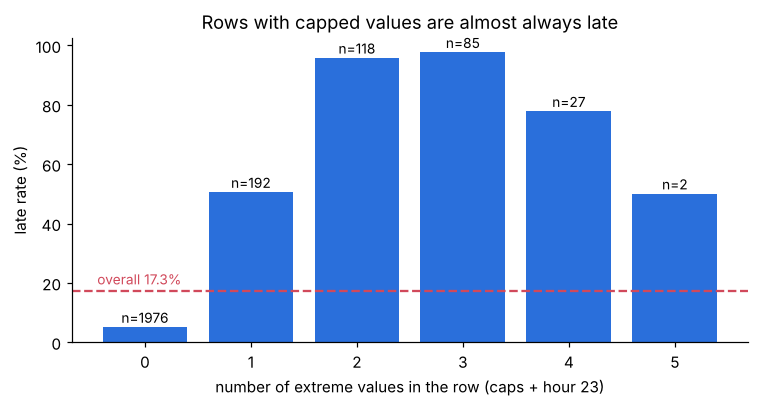

,n,late_rate
n_extreme_flags,,
0,1976,0.051
1,192,0.505
2,118,0.958
3,85,0.976
4,27,0.778
5,2,0.500


In [16]:
g = df.groupby("n_extreme_flags").is_late.agg(n="count", late_rate="mean")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(g.index.astype(str), g.late_rate * 100, color="#2a6fdb")
for i, (n, r) in enumerate(zip(g.n, g.late_rate)):
    ax.text(i, r * 100 + 1.5, f"n={n}", ha="center", fontsize=9)
ax.axhline(df.is_late.mean() * 100, ls="--", color="#d1495b")
ax.text(-0.45, 19.5, "overall 17.3%", color="#d1495b", fontsize=9)
ax.set_xlabel("number of extreme values in the row (caps + hour 23)")
ax.set_ylabel("late rate (%)")
ax.set_title("Rows with capped values are almost always late")
plt.tight_layout(); plt.show()
g.round(3)

**This is the most consequential anomaly in the dataset.**
- 424 rows (17.7%) have at least one capped value or hour 23. Their late rate is **74%**, compared with **5%** for all other rows, and these rows hold **76% of all late legs**.
- With 2+ extreme values, the late rate is about 96%.
- **This could be real or an artifact:**
  - *Real:* the longest, latest, most-stopped legs really are late, and the caps are recording limits on genuinely extreme values. Then the caps are informative and should be kept.
  - *Artifact:* caps and hour 23 come from default fills or the faulty midnight join. Then a model would learn "capped → late", which is a pipeline signature rather than a property of the delivery, and it would fail once the pipeline is fixed.
- **Decision:** keep the values, add `at_cap_<col>` indicator columns, and **evaluate every model with and without these rows**. A large gap between the two would mean the model is mostly learning the artifact. This needs to be raised with Carlos (what produces exactly 420 / 105 / 480 / 22 / 23?).

### 6.5 Multivariate outliers (Isolation Forest)

In [17]:
X = df[NUM].fillna(df[NUM].median())
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=42).fit(X)
df["iso_outlier"] = iso.predict(X) == -1
out = df[df.iso_outlier]
print(f"Isolation Forest flags {len(out)} rows (5%)")
print(f"late rate among outliers: {out.is_late.mean():.1%}  vs  {df.loc[~df.iso_outlier, 'is_late'].mean():.1%} elsewhere")
print(f"outliers that also have >= 1 extreme/capped value: {(out.n_extreme_flags > 0).mean():.1%}")
low = (out[NUM] <= df[NUM].quantile(0.10)).sum(axis=1) >= 2
print(f"outliers with >= 2 features in their bottom 10%: {low.mean():.1%}")
pd.DataFrame({"outliers_median": out[NUM].median(), "all_rows_median": df[NUM].median()}).round(1)

Isolation Forest flags 120 rows (5%)
late rate among outliers: 0.0%  vs  18.2% elsewhere
outliers that also have >= 1 extreme/capped value: 20.8%
outliers with >= 2 features in their bottom 10%: 58.3%


,outliers_median,all_rows_median
scheduled_window_minutes,150.0,282.0
leg_distance_km,125.6,237.9
departure_hour,6.0,13.0
avg_speed_kmh,29.0,62.0
stop_sequence_position,7.0,13.0


**Result: Isolation Forest does *not* find the cap cluster, and what it does flag is not a data problem.**
- The 120 flagged rows are **all on time** (0% late), and only about 21% of them carry a capped value.
- Most of them combine **several unusually low values** (short leg, early hour, early stop, narrow window, slow speed). Because every feature is spread evenly across its range, Isolation Forest simply picks out the "corners" of that space: rare combinations, but plausible deliveries.
- It misses the cap cluster because capped values are **dense** (many rows share exactly the same value), and Isolation Forest only isolates **sparse** points. The caps had to be found with the targeted check in 6.4.

**Takeaway:** for this data, the rule-based checks (§6.1–6.4) are what find the real issues; a generic outlier score does not. The Isolation Forest flags are **not** used for cleaning.

## 7. Relationships to check before modelling

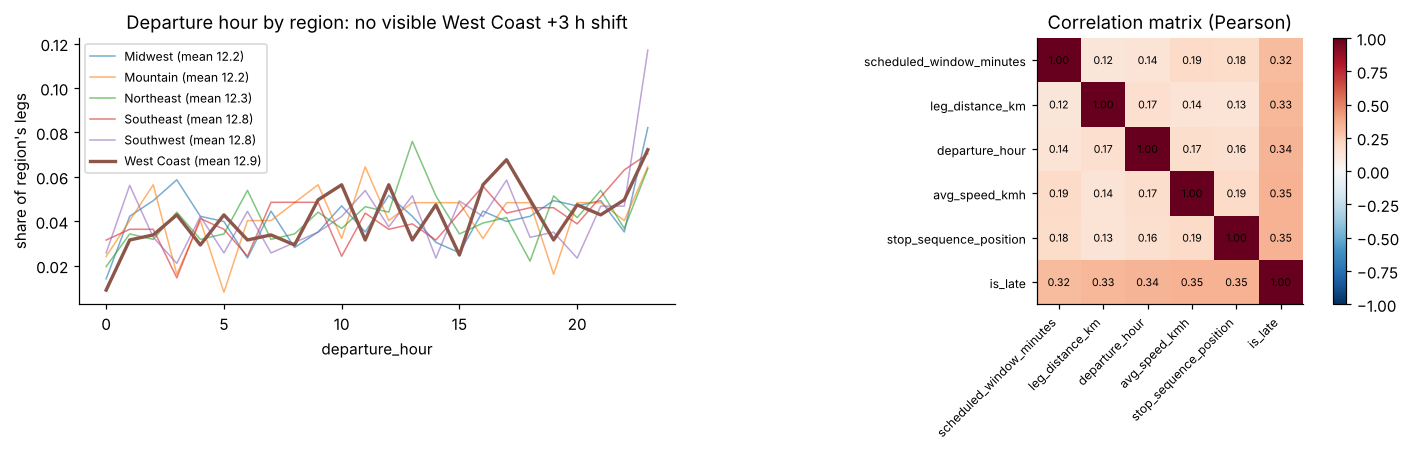

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for r, grp in df.groupby("region"):
    h = grp.departure_hour.dropna()
    ax.plot(h.value_counts(normalize=True).sort_index(), label=f"{r} (mean {h.mean():.1f})",
            lw=2.2 if r == "West Coast" else 1, alpha=1 if r == "West Coast" else .6)
ax.set_xlabel("departure_hour"); ax.set_ylabel("share of region's legs")
ax.set_title("Departure hour by region: no visible West Coast +3 h shift")
ax.legend(fontsize=8)

ax = axes[1]
corr = df[NUM + ["is_late"]].corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Correlation matrix (Pearson)")
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

- **West Coast departure hours are not shifted.** The ML engineer's note says West Coast shifts start 3 hours later, and that `departure_hour` is therefore confounded with region. The distributions overlap almost perfectly, with means within 0.6 h. Either the hours are already normalised to one time zone, or the note describes something not in this extract. **This is unresolved, so don't build a correction for it until it's confirmed.**
- **No strong correlations between features** (|r| ≤ 0.2), so multicollinearity is not a concern. All pairs are weakly *positive* (0.12–0.19), though. Uniform, independently recorded columns shouldn't line up like that. The likely common cause is the cap cluster, where several columns are at their maximum at once (6.4).
- Every numeric feature correlates with `is_late` at almost the same strength (0.32–0.35). That uniformity again suggests one shared driver, the cap cluster, rather than five independent effects. The next cell tests this.

In [19]:
clean = df[df.n_extreme_flags == 0]
cmp = pd.DataFrame({
    "corr_with_is_late_all_rows": df[NUM].corrwith(df.is_late),
    "corr_with_is_late_without_capped_rows": clean[NUM].corrwith(clean.is_late),
})
off = clean[NUM].corr().where(~np.eye(len(NUM), dtype=bool)).abs().max().max()
print(f"rows without any extreme value: {len(clean)}  (late rate {clean.is_late.mean():.1%})")
print(f"max |feature-feature correlation| without capped rows: {off:.2f}")
cmp.round(3)

rows without any extreme value: 1976  (late rate 5.1%)
max |feature-feature correlation| without capped rows: 0.04


,corr_with_is_late_all_rows,corr_with_is_late_without_capped_rows
scheduled_window_minutes,0.318,0.000
leg_distance_km,0.328,0.039
departure_hour,0.341,0.016
avg_speed_kmh,0.349,0.013
stop_sequence_position,0.346,0.027


**Confirmed: once the capped/extreme rows are removed, the numeric features have essentially no linear relationship with lateness** (|r| ≤ 0.04, down from 0.32–0.35), and the positive feature-feature correlations disappear as well.

This is the single most important result of the EDA for modelling. **Almost all of the linear signal in the numeric columns comes from the cap cluster.** If the cluster is a pipeline artifact, a model trained on this data would mostly learn the artifact. The remaining late legs (5.1% of the clean rows) will be much harder to predict, and any non-linear or categorical signal for them still has to be found (weather and vehicle effects, week 2 task 1, §4).

## 8. Prioritised data-quality issues and cleaning decisions

Priority = impact on model validity × number of rows affected.

| # | Priority | Issue | Evidence (this notebook) | Rows | Cleaning decision | Owner / open question |
|---|---|---|---|---|---|---|
| 1 | **P1** | Values piled at hard caps (420 km, 105 km/h, 480 min, stop 22) **and** hour 23, forming a cluster that contains 76% of late legs **and nearly all numeric signal** (|r| drops from ~0.33 to ≤ 0.04 without it) | §4, §6.4, §7 | 424 | **Keep** values; add `at_cap_*` and `n_extreme_flags` indicators; **evaluate every model with and without these rows** | Carlos: are these real caps, defaults, or join artifacts? |
| 2 | **P1** | Hour 23 over-represented (180) and hour 0 under-represented (45), consistent with post-midnight times clipped to 23 (README midnight-join issue) | §6.3 | 180 | Treat `departure_hour = 23` as "late shift, exact hour unknown"; add `hour_23_flag` | Carlos: how are post-midnight departures recorded? |
| 3 | **P1** | Duplicates **can't be detected**: no vehicle ID or timestamp, and every row has its own `leg_id` | §6.1 | unknown | No dedup possible; document the limitation | Carlos: provide `vehicle_id` + timestamp per `leg_id` |
| 4 | **P2** | Missing values in every feature (6.5–7.8%); 43% of rows have at least one gap; `departure_hour` missing is informative (+7 pp late rate) | §3 | 1,039 | **Don't drop rows.** Median/mode imputation inside the CV pipeline, plus missing indicators (always for `departure_hour`) | — |
| 5 | **P2** | Telematics dropouts and implausible speeds: speed missing; < 15 km/h on > 200 km legs; heavy trucks ≥ 100 km/h | §6.2 | 157 missing; 55 crawl; 84 fast trucks | Impute missing speed with an indicator; flag crawl and fast-truck rows (`speed_suspect`) rather than dropping them | Carlos: is the 20% window measured from depot exit or from ignition? |
| 6 | **P2** | `distance / speed` gives unrealistic travel times (351 legs > 8 h; max ≈ 51 h) | §6.3 | 351 | Don't engineer a travel-time feature from early speed and straight-line distance | — |
| 7 | **P3** | Short legs (< 2 km) where the 20% speed window is < 400 m | §6.2 | 6 | Set speed to missing (with indicator) for legs < 2 km | — |
| 8 | **P3** | `demand_spike_flag` True for ~50% of legs and unrelated to lateness | §5 | 2,244 | Keep as is for now; low expected value | Fatima: definition and time grain of the flag |
| 9 | **P3** | Type issues: integer columns stored as float; boolean column stored as object | §1 | all | Cast to `Int64` / nullable `boolean` in the cleaning step | — |
| 10 | **P3** | Window ≤ 1 h on > 300 km legs; window is a destination slot, not a travel budget | §6.3 | 31 | No cleaning; affects how window features are interpreted | Priya: window start/end timestamps? |
| — | info | West Coast +3 h shift from the engineer's note **not observed** | §7 | — | No correction applied | Carlos: time zone of `departure_hour` |
| — | info | `carrier_close_code` is post-outcome | data dictionary | — | Excluded from features | — |

**Next:** these decisions go into the week 3 feature pipeline. The baseline in week 2 task 3 will be reported **with and without** the P1 cluster, so we can see how much of the score comes from it.